In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
from scipy import stats
mpl.rcParams.update(mpl.rcParamsDefault)

In [ ]:
data = pd.read_csv("Students.csv")

print(data.head(10))

   gender race_ethnicity parental_level_of_education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   
5  female        group B          associate's degree      standard   
6  female        group B                some college      standard   
7    male        group B                some college  free/reduced   
8    male        group D                 high school  free/reduced   
9  female        group B                 high school  free/reduced   

  test_preparation_course  math_score  reading_score  writing_score  
0                    none          72             72             74  
1               completed          69             90             88  
2                  

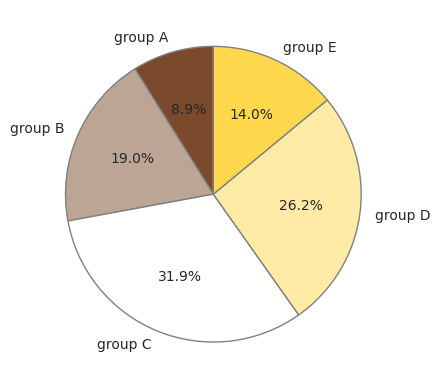

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

# непрерывный cmap: коричневый -> белый -> жёлтый
race_cmap = LinearSegmentedColormap.from_list(
    'race_cmap', ['#7B4A2D', '#FFFFFF', '#FFD84D']
)

# 5 дискретных цветов для групп A–E (по порядку)
race_order = sorted(data['race_ethnicity'].unique())      # A, B, C, D, E
race_colors = [race_cmap(i / (len(race_order) - 1)) for i in range(len(race_order))]
race_palette = dict(zip(race_order, race_colors))

counts = data['race_ethnicity'].value_counts().reindex(race_order)
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90,
        colors=race_colors, wedgeprops=dict(edgecolor='gray', linewidth=1))
plt.show()

In [ ]:
data['Score'] = data['math_score'] + data['reading_score'] + data['writing_score']
print(data[['math_score', 'reading_score', 'writing_score', 'Score']].head())

   math_score  reading_score  writing_score  Score
0          72             72             74    218
1          69             90             88    247
2          90             95             93    278
3          47             57             44    148
4          76             78             75    229


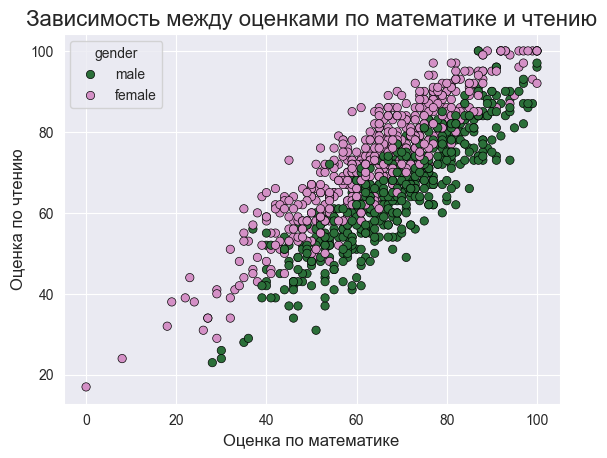

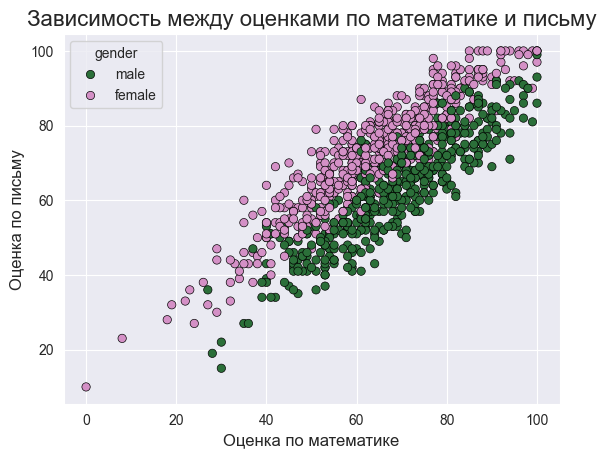

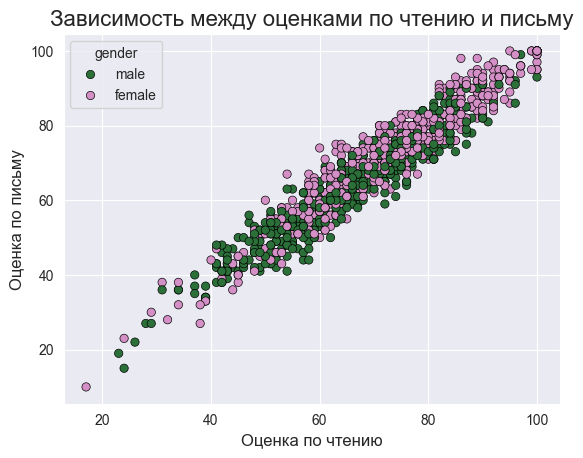

In [ ]:
pairs = [('math_score', 'reading_score', 'Оценка по математике', 'Оценка по чтению', 'математике и чтению'),
         ('math_score', 'writing_score', 'Оценка по математике', 'Оценка по письму', 'математике и письму'),
         ('reading_score', 'writing_score', 'Оценка по чтению', 'Оценка по письму', 'чтению и письму')]

for x, y, xl, yl, t in pairs:
    sns.set_style('darkgrid')
    plt.title(f'Зависимость между оценками по {t}', size=16)
    plt.xlabel(xl, size=12)
    plt.ylabel(yl, size=12)
    sns.scatterplot(x=x, y=y, data=data, hue='gender', edgecolor='black',
                    palette='cubehelix', hue_order=['male', 'female'])
    plt.show()

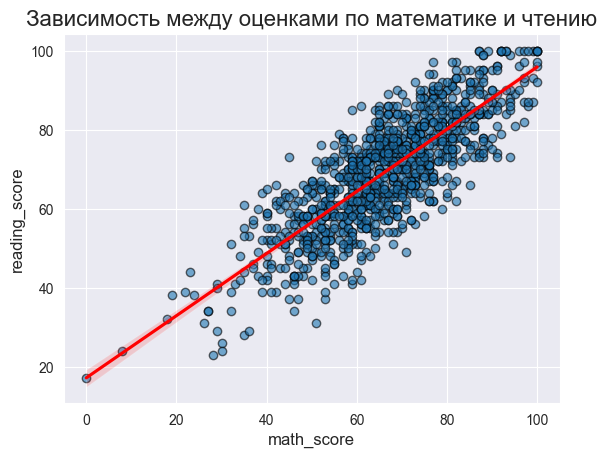

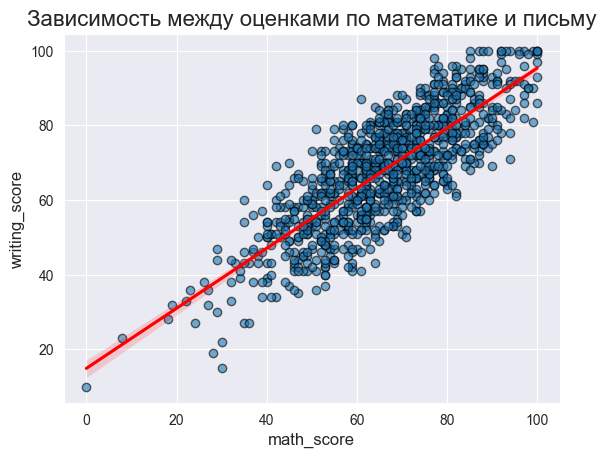

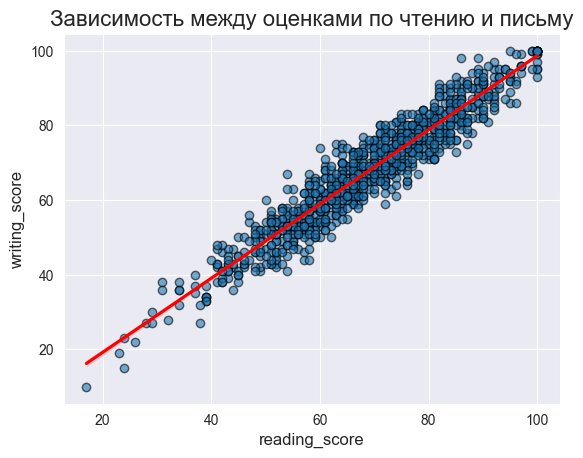

In [ ]:
for x, y, xl, yl, t in pairs:
    sns.set_style('darkgrid')
    plt.title(f'Зависимость между оценками по {t}', size=16)
    plt.xlabel(xl, size=12)
    plt.ylabel(yl, size=12)
    sns.regplot(x=x, y=y, data=data, scatter_kws={'edgecolor': 'black', 'alpha': 0.6},
                line_kws={'color': 'red'})
    plt.show()

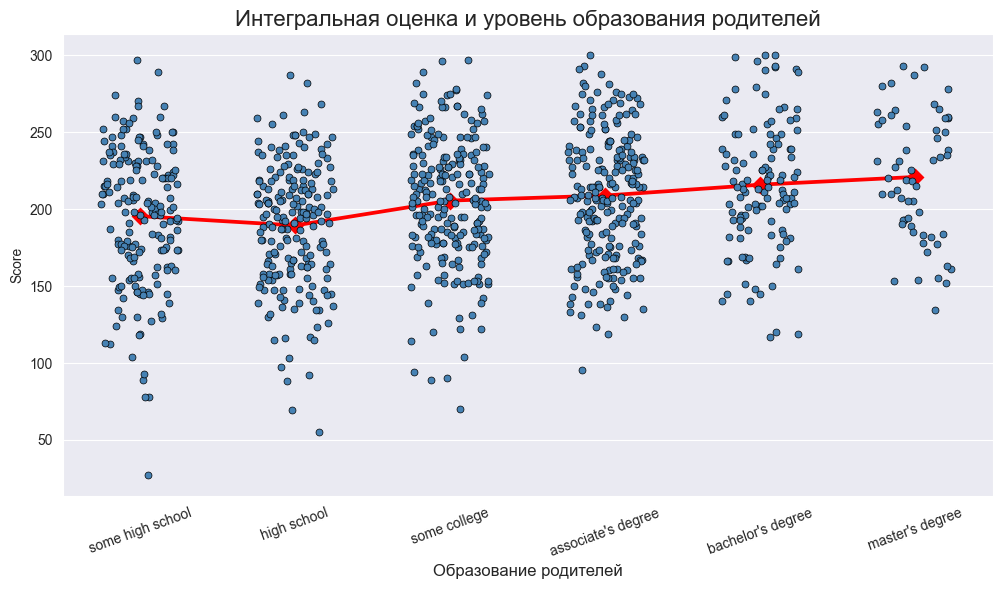

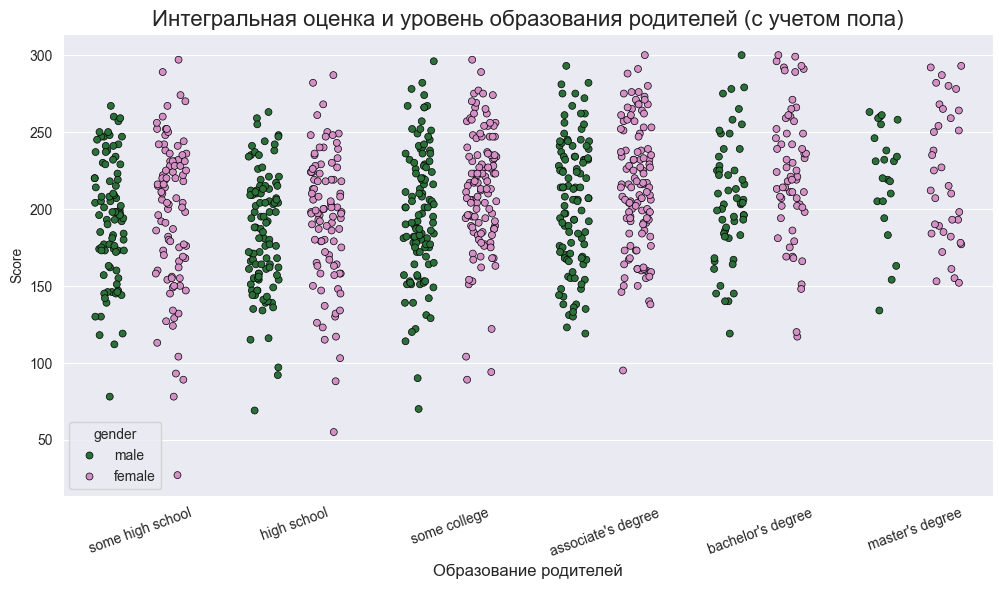

parental_level_of_education
some high school      195.3
high school           189.3
some college          205.4
associate's degree    208.7
bachelor's degree     215.8
master's degree       220.8
Name: Score, dtype: float64
gender                       female   male
parental_level_of_education               
some high school              196.7  193.9
high school                   194.2  184.7
some college                  213.0  197.1
associate's degree            213.4  203.6
bachelor's degree             224.0  206.3
master's degree               220.9  220.6


In [ ]:
edu_order = ['some high school', 'high school', 'some college',
             "associate's degree", "bachelor's degree", "master's degree"]

# без учета пола
plt.figure(figsize=(12, 6))
sns.set_style('darkgrid')
plt.title('Интегральная оценка и уровень образования родителей', size=16)
sns.stripplot(x='parental_level_of_education', y='Score', data=data, order=edu_order,
              jitter=0.25, edgecolor='black', linewidth=0.5, color='steelblue')
sns.pointplot(x='parental_level_of_education', y='Score', data=data, order=edu_order,
              color='red', errorbar=None, markers='D')
plt.xlabel('Образование родителей', size=12)
plt.xticks(rotation=20)
plt.show()

# с учетом пола
plt.figure(figsize=(12, 6))
sns.set_style('darkgrid')
plt.title('Интегральная оценка и уровень образования родителей (с учетом пола)', size=16)
sns.stripplot(x='parental_level_of_education', y='Score', data=data, order=edu_order,
              hue='gender', hue_order=['male', 'female'], dodge=True, jitter=0.2,
              edgecolor='black', linewidth=0.5, palette='cubehelix')
plt.xlabel('Образование родителей', size=12)
plt.xticks(rotation=20)
plt.show()

print(data.groupby('parental_level_of_education')['Score'].mean().loc[edu_order].round(1))
print(data.pivot_table(index='parental_level_of_education', columns='gender',
                       values='Score', aggfunc='mean').loc[edu_order].round(1))

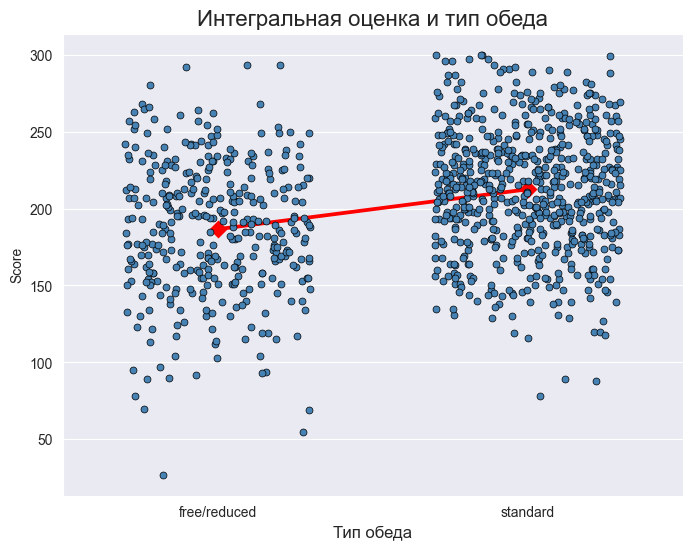

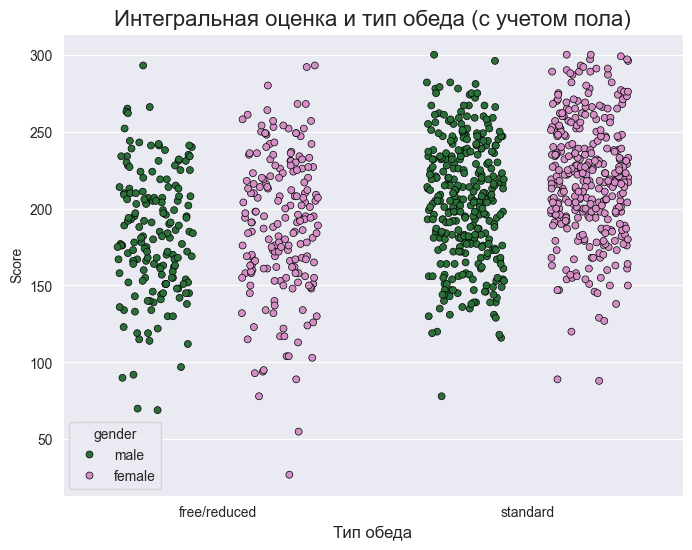

               mean  median  count
lunch                             
free/reduced  186.6   188.0    355
standard      212.5   214.0    645
gender        female   male
lunch                      
free/reduced   189.6  183.1
standard       219.7  205.1


In [ ]:
lunch_order = ['free/reduced', 'standard']

plt.figure(figsize=(8, 6))
sns.set_style('darkgrid')
plt.title('Интегральная оценка и тип обеда', size=16)
sns.stripplot(x='lunch', y='Score', data=data, order=lunch_order, jitter=0.3,
              edgecolor='black', linewidth=0.5, color='steelblue')
sns.pointplot(x='lunch', y='Score', data=data, order=lunch_order, color='red',
              errorbar=None, markers='D')
plt.xlabel('Тип обеда', size=12)
plt.show()

plt.figure(figsize=(8, 6))
sns.set_style('darkgrid')
plt.title('Интегральная оценка и тип обеда (с учетом пола)', size=16)
sns.stripplot(x='lunch', y='Score', data=data, order=lunch_order, hue='gender',
              hue_order=['male', 'female'], dodge=True, jitter=0.25,
              edgecolor='black', linewidth=0.5, palette='cubehelix')
plt.xlabel('Тип обеда', size=12)
plt.show()

print(data.groupby('lunch')['Score'].agg(['mean', 'median', 'count']).round(1))
print(data.pivot_table(index='lunch', columns='gender', values='Score', aggfunc='mean').round(1))

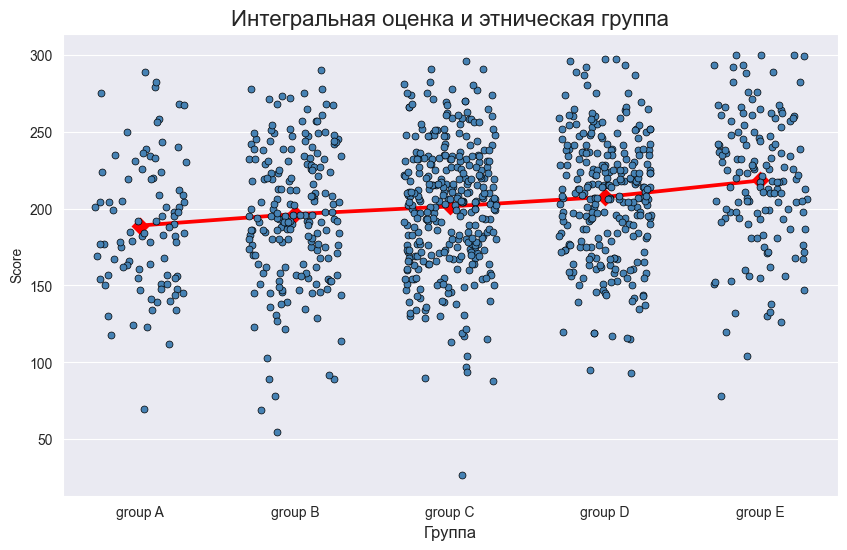

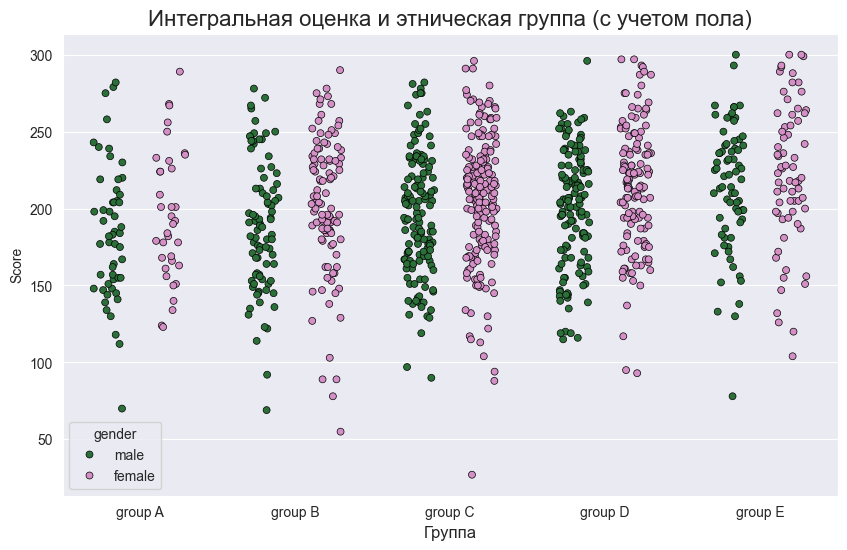

                 mean  count
race_ethnicity              
group A         189.0     89
group B         196.4    190
group C         201.4    319
group D         207.5    262
group E         218.3    140
gender          female   male
race_ethnicity               
group A          195.4  184.6
group B          202.5  189.0
group C          205.8  195.7
group D          214.3  201.0
group E          222.2  214.4


In [ ]:
race_order = sorted(data['race_ethnicity'].unique())

plt.figure(figsize=(10, 6))
sns.set_style('darkgrid')
plt.title('Интегральная оценка и этническая группа', size=16)
sns.stripplot(x='race_ethnicity', y='Score', data=data, order=race_order, jitter=0.3,
              edgecolor='black', linewidth=0.5, color='steelblue')
sns.pointplot(x='race_ethnicity', y='Score', data=data, order=race_order, color='red',
              errorbar=None, markers='D')
plt.xlabel('Группа', size=12)
plt.show()

plt.figure(figsize=(10, 6))
sns.set_style('darkgrid')
plt.title('Интегральная оценка и этническая группа (с учетом пола)', size=16)
sns.stripplot(x='race_ethnicity', y='Score', data=data, order=race_order, hue='gender',
              hue_order=['male', 'female'], dodge=True, jitter=0.2,
              edgecolor='black', linewidth=0.5, palette='cubehelix')
plt.xlabel('Группа', size=12)
plt.show()

print(data.groupby('race_ethnicity')['Score'].agg(['mean', 'count']).round(1))
print(data.pivot_table(index='race_ethnicity', columns='gender', values='Score', aggfunc='mean').round(1))

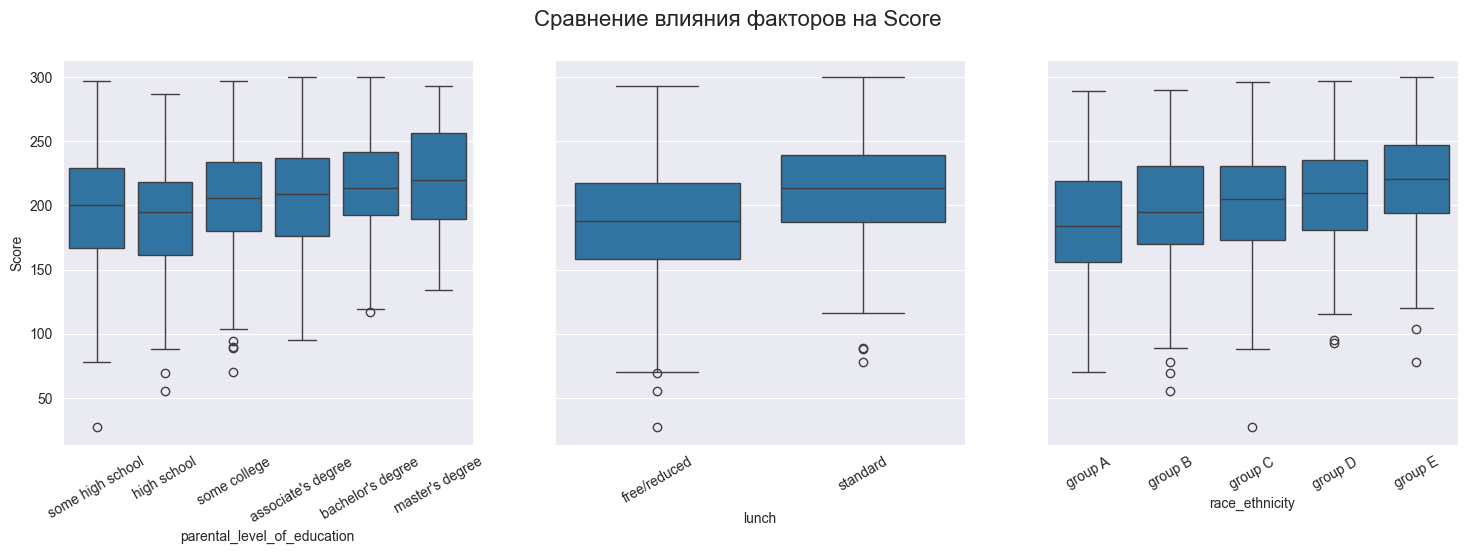

parental_level_of_education    разброс средних = 31.5
lunch                          разброс средних = 25.9
race_ethnicity                 разброс средних = 29.3
lunch           free/reduced  standard
race_ethnicity                        
group A                 0.40      0.60
group B                 0.36      0.64
group C                 0.36      0.64
group D                 0.36      0.64
group E                 0.29      0.71


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, col, order in zip(axes, ['parental_level_of_education', 'lunch', 'race_ethnicity'],
                          [edu_order, lunch_order, race_order]):
    sns.boxplot(x=col, y='Score', data=data, order=order, ax=ax)
    ax.tick_params(axis='x', rotation=30)
plt.suptitle('Сравнение влияния факторов на Score', size=16)
plt.show()

for col in ['parental_level_of_education', 'lunch', 'race_ethnicity']:
    m = data.groupby(col)['Score'].mean()
    print(f'{col:30s} разброс средних = {m.max() - m.min():.1f}')
print(pd.crosstab(data['race_ethnicity'], data['lunch'], normalize='index').round(2))

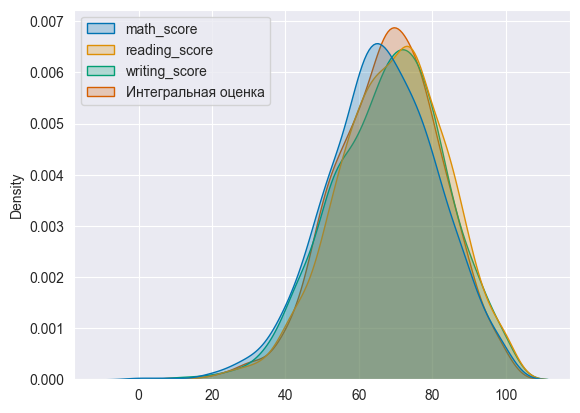

       math_score  reading_score  writing_score  Интегральная оценка
count      1000.0         1000.0         1000.0               1000.0
mean         66.1           69.2           68.1                 67.8
std          15.2           14.6           15.2                 14.3
min           0.0           17.0           10.0                  9.0
25%          57.0           59.0           57.8                 58.3
50%          66.0           70.0           69.0                 68.3
75%          77.0           79.0           79.0                 77.7
max         100.0          100.0          100.0                100.0
math_score             0.919
reading_score          0.970
writing_score          0.966
Интегральная оценка    1.000
Name: Интегральная оценка, dtype: float64


In [ ]:
total_marks = ((data['math_score'] + data['reading_score'] + data['writing_score']) / 300) * 100
data['Интегральная оценка'] = total_marks

kde_data = data[['math_score', 'reading_score', 'writing_score', 'Интегральная оценка']]
sns.set_style("darkgrid")
sns.kdeplot(data=kde_data, fill=True, palette='colorblind')
plt.show()

print(kde_data.describe().round(1))
print(kde_data.corr()['Интегральная оценка'].round(3))

In [ ]:
correlation = data['math_score'].corr(data['reading_score'])
print("r(математика, чтение) =", round(correlation, 3))

correlation = data['math_score'].corr(data['writing_score'])
print("r(математика, письмо) =", round(correlation, 3))

correlation = data['reading_score'].corr(data['writing_score'])
print("r(чтение, письмо)     =", round(correlation, 3))

for x, y in [('math_score', 'reading_score'), ('math_score', 'writing_score'),
             ('reading_score', 'writing_score')]:
    r, p = stats.pearsonr(data[x], data[y])
    print(f'{x} - {y}: r = {r:.3f}, p-value = {p:.2e}')

r(математика, чтение) = 0.818
r(математика, письмо) = 0.803
r(чтение, письмо)     = 0.955
math_score - reading_score: r = 0.818, p-value = 1.79e-241
math_score - writing_score: r = 0.803, p-value = 3.38e-226
reading_score - writing_score: r = 0.955, p-value = 0.00e+00


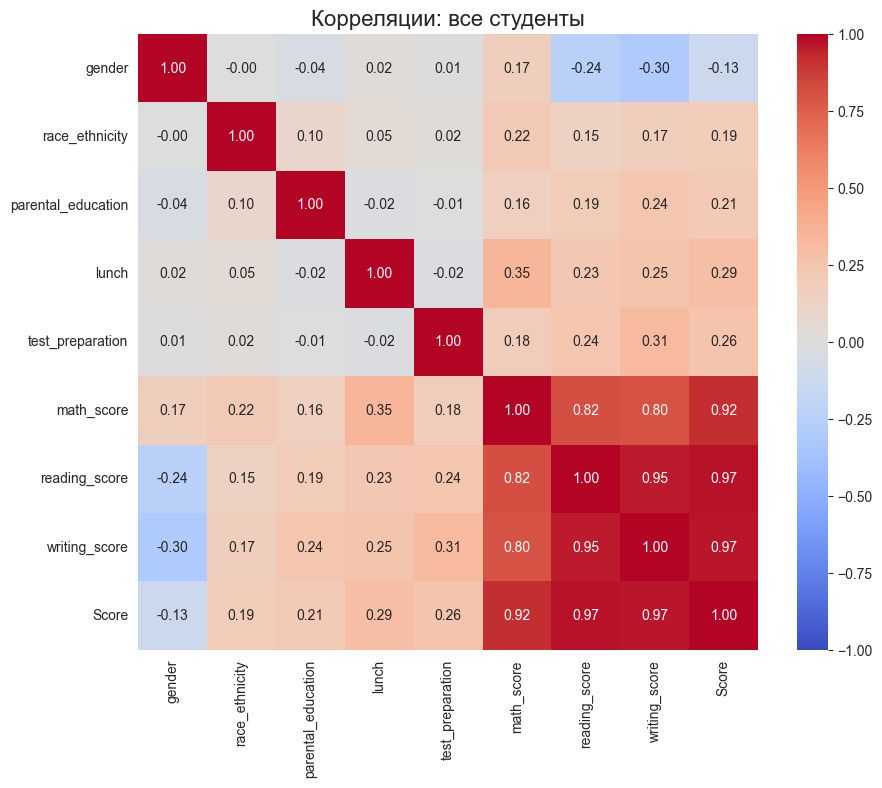

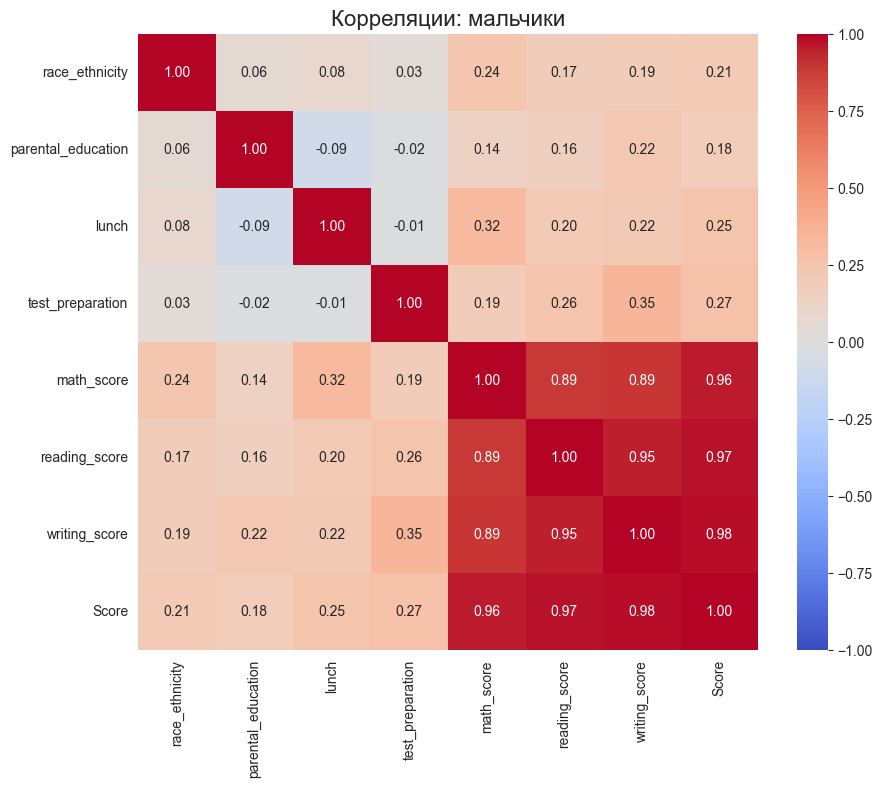

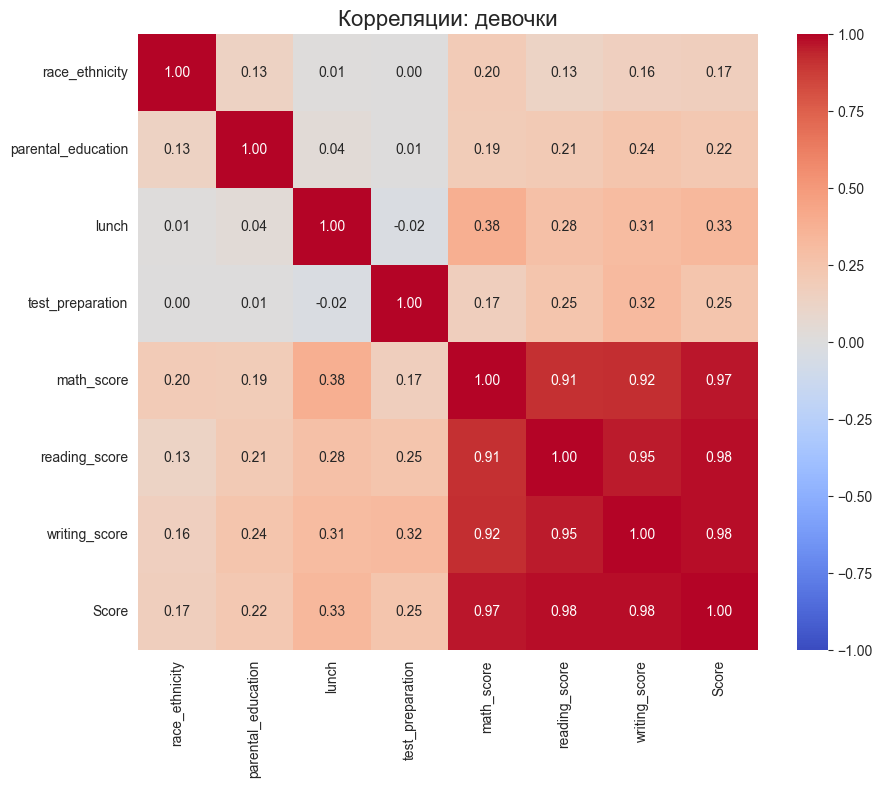

In [ ]:
edu_map = {lvl: i for i, lvl in enumerate(edu_order)}
data_num = pd.DataFrame({
    'gender': (data['gender'] == 'male').astype(int),
    'race_ethnicity': data['race_ethnicity'].map({g: i for i, g in enumerate(race_order)}),
    'parental_education': data['parental_level_of_education'].map(edu_map),
    'lunch': (data['lunch'] == 'standard').astype(int),
    'test_preparation': (data['test_preparation_course'] == 'completed').astype(int),
    'math_score': data['math_score'],
    'reading_score': data['reading_score'],
    'writing_score': data['writing_score'],
    'Score': data['Score'],
})

plt.figure(figsize=(10, 8))
plt.title('Корреляции: все студенты', size=16)
sns.heatmap(data_num.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

for g, name in [(1, 'мальчики'), (0, 'девочки')]:
    sub = data_num[data_num['gender'] == g].drop(columns='gender')
    plt.figure(figsize=(10, 8))
    plt.title(f'Корреляции: {name}', size=16)
    sns.heatmap(sub.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
    plt.show()

In [ ]:
films = pd.read_csv("films.csv")
print(films.head(10))
print(films.shape)
films.info()
print(films.isna().sum())
print('Дубликатов:', films.duplicated().sum())

num_cols = ['popularity', 'budget', 'revenue', 'runtime', 'vote_count', 'vote_average', 'release_year']
print(films[num_cols].describe().round(2))

films['profit'] = films['revenue'] - films['budget']
films['main_genre'] = films['genres'].str.split('|').str[0]

     imdb_id  popularity     budget     revenue                original_title  \
0  tt0369610   32.985763  150000000  1513528810                Jurassic World   
1  tt1392190   28.419936  150000000   378436354            Mad Max: Fury Road   
2  tt2908446   13.112507  110000000   295238201                     Insurgent   
3  tt2488496   11.173104  200000000  2068178225  Star Wars: The Force Awakens   
4  tt2820852    9.335014  190000000  1506249360                     Furious 7   
5  tt1663202    9.110700  135000000   532950503                  The Revenant   
6  tt1340138    8.654359  155000000   440603537            Terminator Genisys   
7  tt3659388    7.667400  108000000   595380321                   The Martian   
8  tt2293640    7.404165   74000000  1156730962                       Minions   
9  tt2096673    6.326804  175000000   853708609                    Inside Out   

                                                cast  \
0  Chris Pratt|Bryce Dallas Howard|Irrfan Khan|Vi...

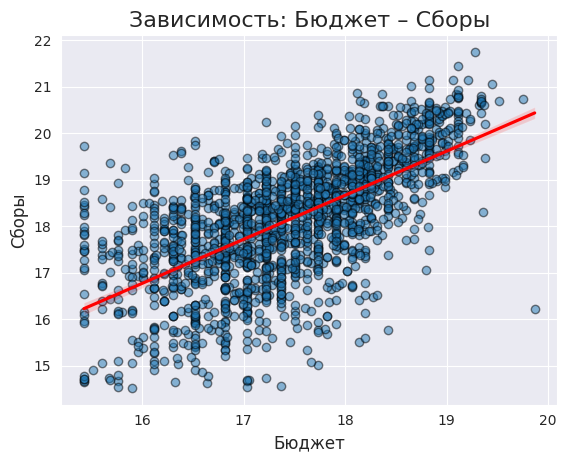

r(log_budget, log_revenue) = 0.649


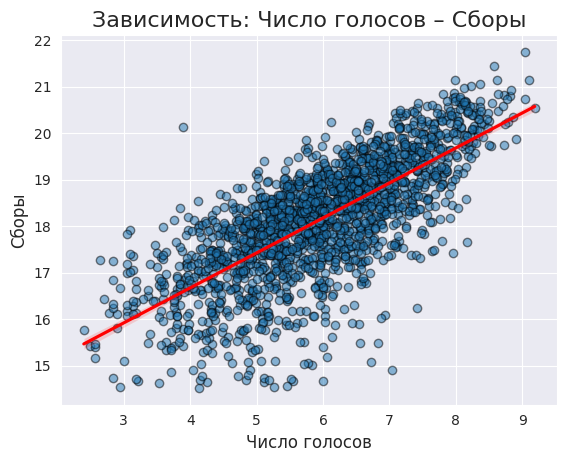

r(log_vote_count, log_revenue) = 0.735


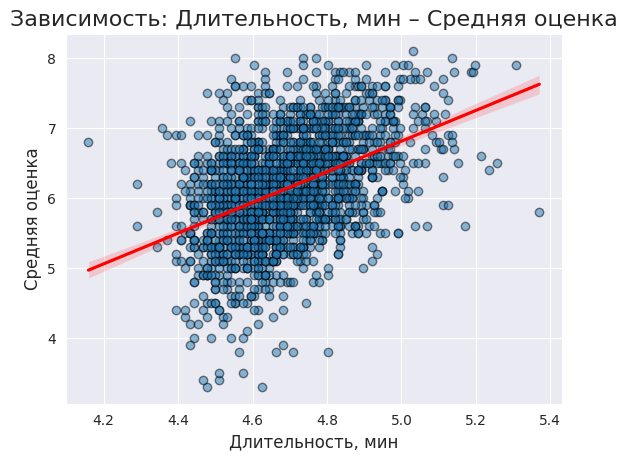

r(log_runtime, vote_average) = 0.445


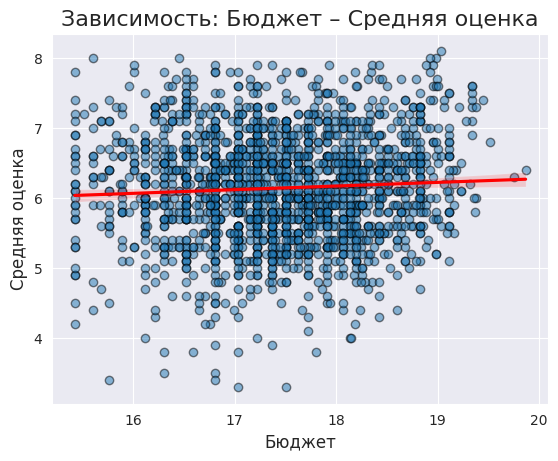

r(log_budget, vote_average) = 0.060


In [ ]:

films['log_revenue'] = np.log1p(films['revenue'])
films['log_vote_count'] = np.log1p(films['vote_count'])
films['log_runtime'] = np.log1p(films['runtime'])

for x, y, xl, yl in [('log_budget', 'log_revenue', 'Бюджет', 'Сборы'),
                     ('log_vote_count', 'log_revenue', 'Число голосов', 'Сборы'),
                     ('log_runtime', 'vote_average', 'Длительность, мин', 'Средняя оценка'),
                     ('log_budget', 'vote_average', 'Бюджет', 'Средняя оценка')]:
    sns.set_style('darkgrid')
    plt.title(f'Зависимость: {xl} – {yl}', size=16)
    sns.regplot(x=x, y=y, data=films, scatter_kws={'edgecolor': 'black', 'alpha': 0.5},
                line_kws={'color': 'red'})
    plt.xlabel(xl, size=12)
    plt.ylabel(yl, size=12)
    plt.show()
    print(f'r({x}, {y}) = {films[x].corr(films[y]):.3f}')

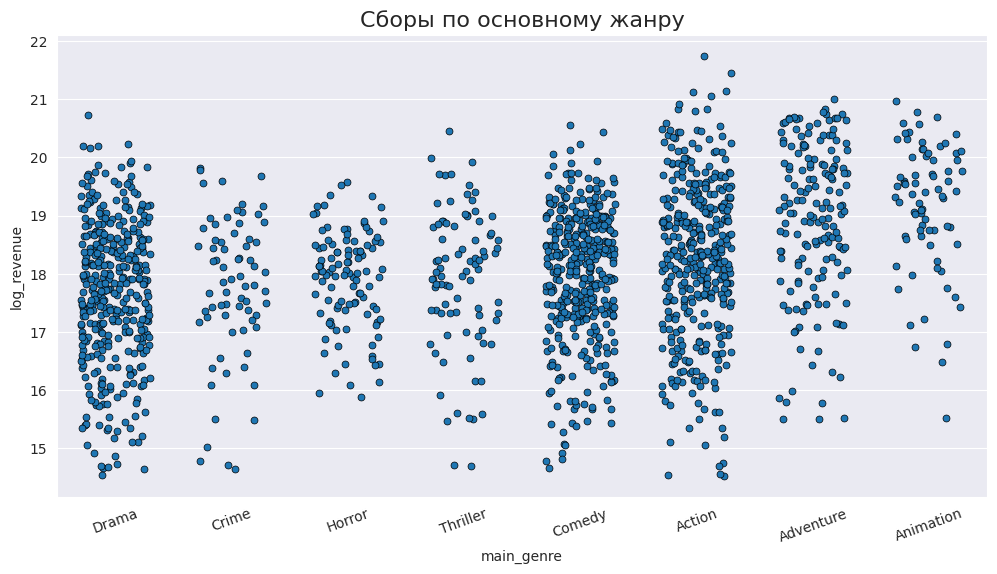

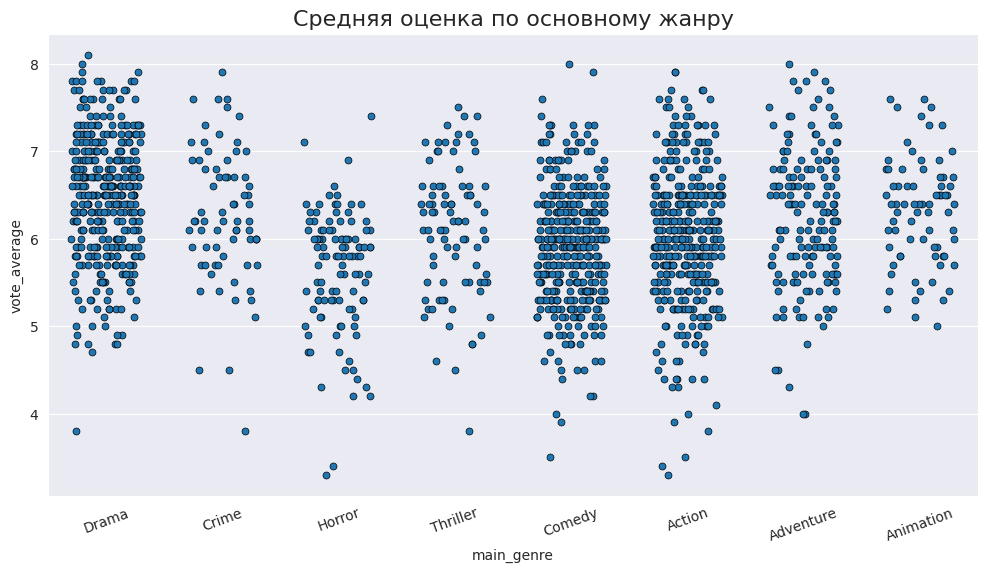

                revenue  vote_average
main_genre                           
Drama        54600000.0           6.5
Crime        56714147.0           6.2
Horror       68291756.5           5.8
Thriller     69790856.0           6.2
Comedy       73684830.0           5.9
Action       91731514.5           6.0
Adventure   200368305.5           6.3
Animation   260696994.0           6.4


In [ ]:
top_genres = films['main_genre'].value_counts().head(8).index
films_top = films[films['main_genre'].isin(top_genres)]
genre_order = films_top.groupby('main_genre')['log_revenue'].median().sort_values().index

plt.figure(figsize=(12, 6))
sns.set_style('darkgrid')
plt.title('Сборы по основному жанру', size=16)
sns.stripplot(x='main_genre', y='log_revenue', data=films_top, order=genre_order,
              jitter=0.3, edgecolor='black', linewidth=0.5)
plt.xticks(rotation=20)
plt.show()

plt.figure(figsize=(12, 6))
sns.set_style('darkgrid')
plt.title('Средняя оценка по основному жанру', size=16)
sns.stripplot(x='main_genre', y='vote_average', data=films_top, order=genre_order,
              jitter=0.3, edgecolor='black', linewidth=0.5)
plt.xticks(rotation=20)
plt.show()

print(films_top.groupby('main_genre')[['revenue', 'vote_average']].median().loc[genre_order].round(1))

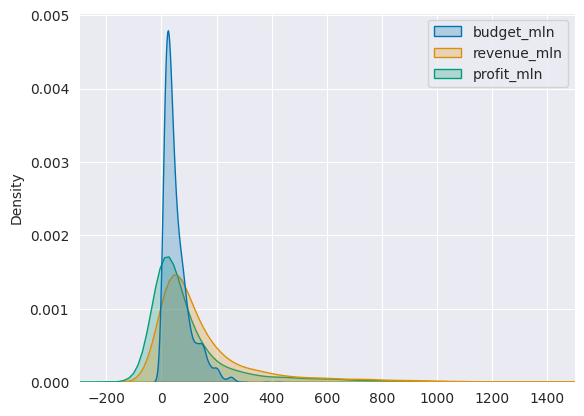

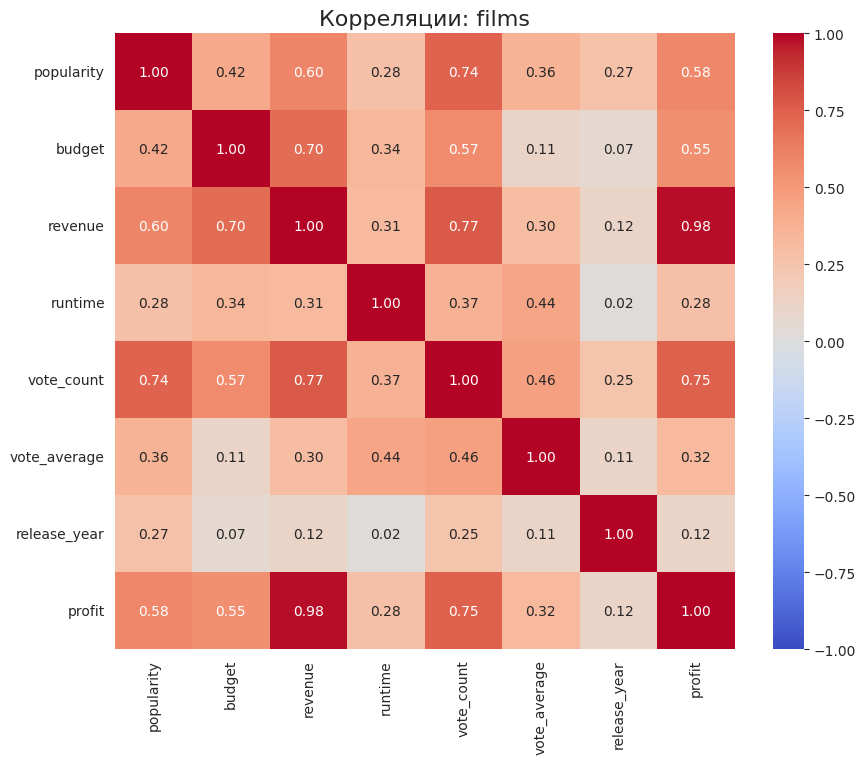

In [ ]:
films['budget_mln'] = films['budget'] / 1e6
films['revenue_mln'] = films['revenue'] / 1e6
films['profit_mln'] = films['profit'] / 1e6

sns.set_style("darkgrid")
sns.kdeplot(data=films[['budget_mln', 'revenue_mln', 'profit_mln']], fill=True, palette='colorblind')
plt.xlim(-300, 1500)
plt.show()

plt.figure(figsize=(10, 8))
plt.title('Корреляции: films', size=16)
sns.heatmap(films[num_cols + ['profit']].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.show()